# 🐾 PawCare Unified Pet Prediction

## Cat + Dog Breed Classification

This notebook combines the trained PawCare AI models into one unified prediction system.

### Pipeline

Image
↓
Cat vs Non-Cat Detector
↓
├── Cat → Cat Breed Classifier
│
└── Non-Cat → Dog vs Non-Dog Detector
              ↓
              ├── Dog → Dog Breed Classifier
              │
              └── Non-Dog → Neither Cat nor Dog

### Supported Breeds

🐱 11 Cat Breeds

🐶 10 Dog Breeds

In [1]:
import os
import json
import numpy as np
import tensorflow as tf

from PIL import Image
import matplotlib.pyplot as plt
from tkinter import Tk, filedialog

print("TensorFlow version:", tf.__version__)
print("Unified PawCare environment loaded successfully!")

TensorFlow version: 2.21.0
Unified PawCare environment loaded successfully!


In [2]:
# ============================================================
# PROJECT PATHS
# ============================================================

# Notebook location:
# PawCare/
# └── notebooks/
#     └── unified_pet_prediction.ipynb
#
# Going up:
# notebooks -> PawCare

PROJECT_ROOT = os.path.abspath(
    os.path.join(
        os.getcwd(),
        ".."
    )
)

print("Project root:")
print(PROJECT_ROOT)

Project root:
c:\Users\saisa\OneDrive\Documents\PawCare


In [3]:
# ============================================================
# CAT MODEL PATHS
# ============================================================

CAT_DETECTOR_MODEL_PATH = os.path.join(
    PROJECT_ROOT,
    "models",
    "cat_detector.keras"
)

CAT_DETECTOR_CLASSES_PATH = os.path.join(
    PROJECT_ROOT,
    "models",
    "cat_detector_class_names.json"
)

CAT_BREED_MODEL_PATH = os.path.join(
    PROJECT_ROOT,
    "models",
    "cat_breed_classifier.keras"
)

CAT_BREED_CLASSES_PATH = os.path.join(
    PROJECT_ROOT,
    "models",
    "class_names.json"
)


# ============================================================
# DOG MODEL PATHS
# ============================================================

DOG_DETECTOR_MODEL_PATH = os.path.join(
    PROJECT_ROOT,
    "dog_breed",
    "dog_detector",
    "models",
    "dog_detector.keras"
)

DOG_DETECTOR_CLASSES_PATH = os.path.join(
    PROJECT_ROOT,
    "dog_breed",
    "dog_detector",
    "models",
    "dog_detector_class_names.json"
)

DOG_BREED_MODEL_PATH = os.path.join(
    PROJECT_ROOT,
    "dog_breed",
    "models",
    "dog_breed_classifier.keras"
)

DOG_BREED_CLASSES_PATH = os.path.join(
    PROJECT_ROOT,
    "dog_breed",
    "models",
    "dog_class_names.json"
)


IMG_SIZE = 224

print("Model paths configured.")

Model paths configured.


In [4]:
# ============================================================
# CHECK REQUIRED FILES
# ============================================================

required_files = {
    "Cat Detector": CAT_DETECTOR_MODEL_PATH,
    "Cat Detector Classes": CAT_DETECTOR_CLASSES_PATH,
    "Cat Breed Classifier": CAT_BREED_MODEL_PATH,
    "Cat Breed Classes": CAT_BREED_CLASSES_PATH,
    "Dog Detector": DOG_DETECTOR_MODEL_PATH,
    "Dog Detector Classes": DOG_DETECTOR_CLASSES_PATH,
    "Dog Breed Classifier": DOG_BREED_MODEL_PATH,
    "Dog Breed Classes": DOG_BREED_CLASSES_PATH
}

all_files_found = True

for name, path in required_files.items():

    if os.path.exists(path):
        print(f"✅ {name}")
    else:
        print(f"❌ MISSING: {name}")
        print(path)
        all_files_found = False

if all_files_found:
    print("\n✅ All required model files found!")
else:
    print("\n❌ Some model files are missing.")

✅ Cat Detector
✅ Cat Detector Classes
✅ Cat Breed Classifier
✅ Cat Breed Classes
✅ Dog Detector
✅ Dog Detector Classes
✅ Dog Breed Classifier
✅ Dog Breed Classes

✅ All required model files found!


In [5]:
# ============================================================
# LOAD CAT MODELS
# ============================================================

cat_detector_model = tf.keras.models.load_model(
    CAT_DETECTOR_MODEL_PATH
)

with open(
    CAT_DETECTOR_CLASSES_PATH,
    "r"
) as file:
    cat_detector_classes = json.load(file)


cat_breed_model = tf.keras.models.load_model(
    CAT_BREED_MODEL_PATH
)

with open(
    CAT_BREED_CLASSES_PATH,
    "r"
) as file:
    cat_breed_classes = json.load(file)


print("✅ Cat detector loaded!")
print("Cat detector classes:", cat_detector_classes)

print()

print("✅ Cat breed classifier loaded!")
print("Number of cat breeds:", len(cat_breed_classes))
print("Cat breeds:")

for breed in cat_breed_classes:
    print("-", breed.replace("_", " "))

✅ Cat detector loaded!
Cat detector classes: ['cat', 'non_cat']

✅ Cat breed classifier loaded!
Number of cat breeds: 11
Cat breeds:
- Abyssinian
- Bengal
- Bombay
- British Shorthair
- Egyptian Mau
- Maine Coon
- Persian
- Ragdoll
- Russian Blue
- Siamese
- Sphynx


In [6]:
# ============================================================
# LOAD DOG MODELS
# ============================================================

dog_detector_model = tf.keras.models.load_model(
    DOG_DETECTOR_MODEL_PATH
)

with open(
    DOG_DETECTOR_CLASSES_PATH,
    "r"
) as file:
    dog_detector_classes = json.load(file)


dog_breed_model = tf.keras.models.load_model(
    DOG_BREED_MODEL_PATH
)

with open(
    DOG_BREED_CLASSES_PATH,
    "r"
) as file:
    dog_breed_classes = json.load(file)


print("✅ Dog detector loaded!")
print("Dog detector classes:", dog_detector_classes)

print()

print("✅ Dog breed classifier loaded!")
print("Number of dog breeds:", len(dog_breed_classes))
print("Dog breeds:")

for breed in dog_breed_classes:
    print("-", breed.replace("_", " "))

✅ Dog detector loaded!
Dog detector classes: ['dog', 'non_dog']

✅ Dog breed classifier loaded!
Number of dog breeds: 10
Dog breeds:
- German shepherd
- Siberian husky
- Yorkshire terrier
- beagle
- boxer
- golden retriever
- pug
- shitzu
- standard poodle
- whippet


In [7]:
# ============================================================
# SELECT IMAGE
# ============================================================

root = Tk()
root.withdraw()

image_path = filedialog.askopenfilename(
    title="Select a Pet Image",
    filetypes=[
        (
            "Image Files",
            "*.jpg *.jpeg *.png *.bmp *.webp"
        )
    ]
)

root.destroy()

if image_path:
    print("Selected image:")
    print(image_path)
else:
    print("No image selected.")

Selected image:
C:/Users/saisa/Downloads/non_cat dataset/shitzu/n02086240_1770.jpg


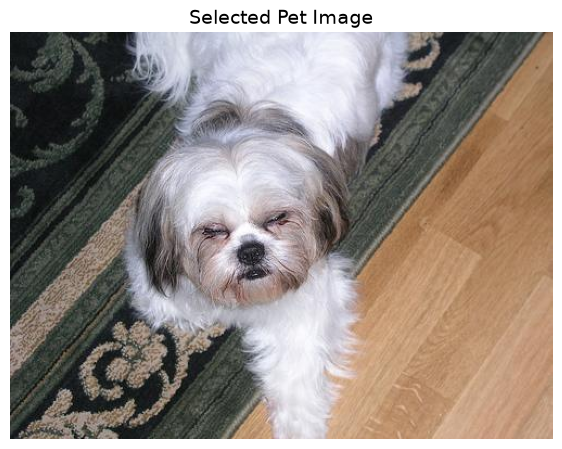

In [8]:
# ============================================================
# DISPLAY SELECTED IMAGE
# ============================================================

if image_path:

    original_image = Image.open(
        image_path
    ).convert("RGB")

    plt.figure(figsize=(7, 7))

    plt.imshow(original_image)

    plt.axis("off")

    plt.title(
        "Selected Pet Image",
        fontsize=14
    )

    plt.show()

else:

    print("Please select an image first.")

In [9]:
# ============================================================
# IMAGE PREPROCESSING
# ============================================================

if image_path:

    image = original_image.resize(
        (IMG_SIZE, IMG_SIZE)
    )

    image_array = np.array(
        image,
        dtype=np.float32
    )

    image_array = np.expand_dims(
        image_array,
        axis=0
    )

    print("Image prepared successfully.")
    print("Input shape:", image_array.shape)
    print("Data type:", image_array.dtype)

Image prepared successfully.
Input shape: (1, 224, 224, 3)
Data type: float32


In [10]:
# ============================================================
# STAGE 1 - CAT VS NON-CAT
# ============================================================

if image_path:

    cat_detector_predictions = (
        cat_detector_model.predict(
            image_array,
            verbose=0
        )[0]
    )

    cat_detector_index = np.argmax(
        cat_detector_predictions
    )

    cat_detected_class = (
        cat_detector_classes[
            cat_detector_index
        ]
    )

    cat_detector_confidence = (
        cat_detector_predictions[
            cat_detector_index
        ] * 100
    )

    print("Cat Detector Result")
    print("-------------------")

    print(
        "Class:",
        cat_detected_class
    )

    print(
        f"Confidence: "
        f"{cat_detector_confidence:.2f}%"
    )

Cat Detector Result
-------------------
Class: non_cat
Confidence: 83.82%


In [11]:
# ============================================================
# UNIFIED PET PREDICTION
# ============================================================

if image_path:

    # ========================================================
    # CAT PATH
    # ========================================================

    if cat_detected_class == "cat":

        print("=" * 60)
        print("🐱 CAT DETECTED")
        print("=" * 60)

        cat_breed_predictions = (
            cat_breed_model.predict(
                image_array,
                verbose=0
            )[0]
        )

        cat_top_indices = np.argsort(
            cat_breed_predictions
        )[::-1][:3]

        print("\nTop 3 Cat Breed Predictions:\n")

        for rank, index in enumerate(
            cat_top_indices,
            start=1
        ):

            breed = cat_breed_classes[index]

            confidence = (
                cat_breed_predictions[index] * 100
            )

            print(
                f"{rank}. "
                f"{breed.replace('_', ' ')} "
                f"- {confidence:.2f}%"
            )

        best_index = cat_top_indices[0]

        best_breed = cat_breed_classes[
            best_index
        ]

        best_confidence = (
            cat_breed_predictions[
                best_index
            ] * 100
        )

        print("\n" + "=" * 60)
        print("FINAL RESULT")
        print("=" * 60)

        print("Animal:", "Cat")
        print(
            "Breed:",
            best_breed.replace("_", " ")
        )
        print(
            f"Breed Confidence: "
            f"{best_confidence:.2f}%"
        )


    # ========================================================
    # NON-CAT → DOG PATH
    # ========================================================

    else:

        print("=" * 60)
        print("Image is not detected as a cat.")
        print("Checking for dog...")
        print("=" * 60)

        dog_detector_predictions = (
            dog_detector_model.predict(
                image_array,
                verbose=0
            )[0]
        )

        dog_detector_index = np.argmax(
            dog_detector_predictions
        )

        dog_detected_class = (
            dog_detector_classes[
                dog_detector_index
            ]
        )

        dog_detector_confidence = (
            dog_detector_predictions[
                dog_detector_index
            ] * 100
        )

        print("\nDog Detector Result")
        print("-------------------")

        print(
            "Class:",
            dog_detected_class
        )

        print(
            f"Confidence: "
            f"{dog_detector_confidence:.2f}%"
        )


        # ====================================================
        # DOG PATH
        # ====================================================

        if dog_detected_class == "dog":

            print()
            print("=" * 60)
            print("🐶 DOG DETECTED")
            print("=" * 60)

            dog_breed_predictions = (
                dog_breed_model.predict(
                    image_array,
                    verbose=0
                )[0]
            )

            dog_top_indices = np.argsort(
                dog_breed_predictions
            )[::-1][:3]

            print(
                "\nTop 3 Dog Breed Predictions:\n"
            )

            for rank, index in enumerate(
                dog_top_indices,
                start=1
            ):

                breed = dog_breed_classes[index]

                confidence = (
                    dog_breed_predictions[
                        index
                    ] * 100
                )

                print(
                    f"{rank}. "
                    f"{breed.replace('_', ' ')} "
                    f"- {confidence:.2f}%"
                )

            best_index = dog_top_indices[0]

            best_breed = dog_breed_classes[
                best_index
            ]

            best_confidence = (
                dog_breed_predictions[
                    best_index
                ] * 100
            )

            print("\n" + "=" * 60)
            print("FINAL RESULT")
            print("=" * 60)

            print("Animal:", "Dog")

            print(
                "Breed:",
                best_breed.replace("_", " ")
            )

            print(
                f"Breed Confidence: "
                f"{best_confidence:.2f}%"
            )


        # ====================================================
        # NEITHER CAT NOR DOG
        # ====================================================

        else:

            print()
            print("=" * 60)
            print("❌ NEITHER CAT NOR DOG")
            print("=" * 60)

            print(
                "This image is not detected as a cat or dog."
            )

            print(
                "Breed classification skipped."
            )

Image is not detected as a cat.
Checking for dog...

Dog Detector Result
-------------------
Class: dog
Confidence: 93.85%

🐶 DOG DETECTED

Top 3 Dog Breed Predictions:

1. shitzu - 91.50%
2. Yorkshire terrier - 4.59%
3. pug - 1.28%

FINAL RESULT
Animal: Dog
Breed: shitzu
Breed Confidence: 91.50%


c:\Users\saisa\OneDrive\Documents\PawCare\venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 128054 (\N{DOG FACE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


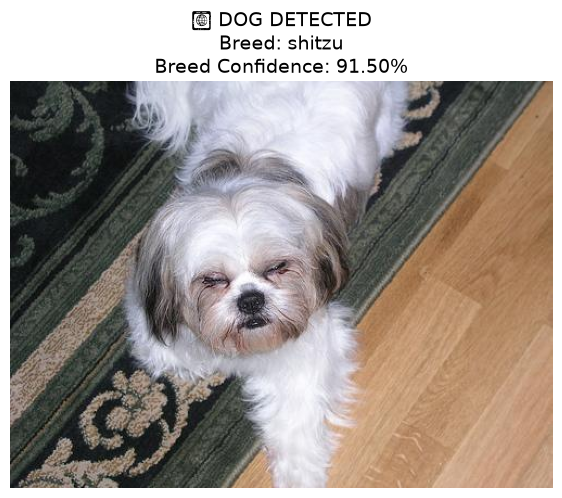

In [12]:
# ============================================================
# FINAL PREDICTION WITH IMAGE
# ============================================================

if image_path:

    plt.figure(figsize=(7, 7))

    plt.imshow(original_image)

    plt.axis("off")

    # --------------------------------------------------------
    # CAT RESULT
    # --------------------------------------------------------

    if cat_detected_class == "cat":

        plt.title(
            "🐱 CAT DETECTED\n"
            f"Breed: "
            f"{best_breed.replace('_', ' ')}\n"
            f"Breed Confidence: "
            f"{best_confidence:.2f}%",
            fontsize=14
        )

    # --------------------------------------------------------
    # DOG RESULT
    # --------------------------------------------------------

    elif dog_detected_class == "dog":

        plt.title(
            "🐶 DOG DETECTED\n"
            f"Breed: "
            f"{best_breed.replace('_', ' ')}\n"
            f"Breed Confidence: "
            f"{best_confidence:.2f}%",
            fontsize=14
        )

    # --------------------------------------------------------
    # NEITHER
    # --------------------------------------------------------

    else:

        plt.title(
            "❌ NEITHER CAT NOR DOG\n"
            "Breed classification skipped.",
            fontsize=14
        )

    plt.show()

In [13]:
# ============================================================
# ONE-CLICK UNIFIED PET PREDICTION
# ============================================================

def pawcare_unified_predict():

    print("=" * 60)
    print("🐾 PAWCARE UNIFIED PET AI")
    print("=" * 60)

    # --------------------------------------------------------
    # SELECT IMAGE
    # --------------------------------------------------------

    root = Tk()
    root.withdraw()

    selected_path = filedialog.askopenfilename(
        title="Select a Pet Image",
        filetypes=[
            (
                "Image Files",
                "*.jpg *.jpeg *.png *.bmp *.webp"
            )
        ]
    )

    root.destroy()

    if not selected_path:

        print("No image selected.")

        return


    # --------------------------------------------------------
    # LOAD IMAGE
    # --------------------------------------------------------

    selected_image = Image.open(
        selected_path
    ).convert("RGB")


    # --------------------------------------------------------
    # DISPLAY IMAGE
    # --------------------------------------------------------

    plt.figure(figsize=(6, 6))

    plt.imshow(selected_image)

    plt.axis("off")

    plt.title(
        "Selected Image",
        fontsize=14
    )

    plt.show()


    # --------------------------------------------------------
    # PREPROCESS
    # --------------------------------------------------------

    resized_image = selected_image.resize(
        (IMG_SIZE, IMG_SIZE)
    )

    input_array = np.array(
        resized_image,
        dtype=np.float32
    )

    input_array = np.expand_dims(
        input_array,
        axis=0
    )


    # ========================================================
    # CAT DETECTOR
    # ========================================================

    cat_predictions = (
        cat_detector_model.predict(
            input_array,
            verbose=0
        )[0]
    )

    cat_index = np.argmax(
        cat_predictions
    )

    cat_class = cat_detector_classes[
        cat_index
    ]

    cat_confidence = (
        cat_predictions[
            cat_index
        ] * 100
    )


    # ========================================================
    # CAT
    # ========================================================

    if cat_class == "cat":

        breed_predictions = (
            cat_breed_model.predict(
                input_array,
                verbose=0
            )[0]
        )

        top_indices = np.argsort(
            breed_predictions
        )[::-1][:3]

        best_index = top_indices[0]

        best_breed = cat_breed_classes[
            best_index
        ]

        best_confidence = (
            breed_predictions[
                best_index
            ] * 100
        )

        print()
        print("=" * 60)
        print("🐱 FINAL RESULT")
        print("=" * 60)

        print(
            f"Animal: CAT"
        )

        print(
            f"Breed: "
            f"{best_breed.replace('_', ' ')}"
        )

        print(
            f"Breed Confidence: "
            f"{best_confidence:.2f}%"
        )

        print("\nTop 3 Predictions:")

        for rank, index in enumerate(
            top_indices,
            start=1
        ):

            breed = cat_breed_classes[index]

            confidence = (
                breed_predictions[index] * 100
            )

            print(
                f"{rank}. "
                f"{breed.replace('_', ' ')} "
                f"- {confidence:.2f}%"
            )


        # ----------------------------------------------------
        # DISPLAY FINAL RESULT
        # ----------------------------------------------------

        plt.figure(figsize=(7, 7))

        plt.imshow(selected_image)

        plt.axis("off")

        plt.title(
            "🐱 CAT DETECTED\n"
            f"Breed: "
            f"{best_breed.replace('_', ' ')}\n"
            f"Confidence: "
            f"{best_confidence:.2f}%",
            fontsize=14
        )

        plt.show()

        return


    # ========================================================
    # DOG DETECTOR
    # ========================================================

    dog_predictions = (
        dog_detector_model.predict(
            input_array,
            verbose=0
        )[0]
    )

    dog_index = np.argmax(
        dog_predictions
    )

    dog_class = dog_detector_classes[
        dog_index
    ]

    dog_confidence = (
        dog_predictions[
            dog_index
        ] * 100
    )


    # ========================================================
    # DOG
    # ========================================================

    if dog_class == "dog":

        breed_predictions = (
            dog_breed_model.predict(
                input_array,
                verbose=0
            )[0]
        )

        top_indices = np.argsort(
            breed_predictions
        )[::-1][:3]

        best_index = top_indices[0]

        best_breed = dog_breed_classes[
            best_index
        ]

        best_confidence = (
            breed_predictions[
                best_index
            ] * 100
        )

        print()
        print("=" * 60)
        print("🐶 FINAL RESULT")
        print("=" * 60)

        print(
            "Animal: DOG"
        )

        print(
            f"Breed: "
            f"{best_breed.replace('_', ' ')}"
        )

        print(
            f"Breed Confidence: "
            f"{best_confidence:.2f}%"
        )

        print("\nTop 3 Predictions:")

        for rank, index in enumerate(
            top_indices,
            start=1
        ):

            breed = dog_breed_classes[index]

            confidence = (
                breed_predictions[index] * 100
            )

            print(
                f"{rank}. "
                f"{breed.replace('_', ' ')} "
                f"- {confidence:.2f}%"
            )


        # ----------------------------------------------------
        # DISPLAY FINAL RESULT
        # ----------------------------------------------------

        plt.figure(figsize=(7, 7))

        plt.imshow(selected_image)

        plt.axis("off")

        plt.title(
            "🐶 DOG DETECTED\n"
            f"Breed: "
            f"{best_breed.replace('_', ' ')}\n"
            f"Confidence: "
            f"{best_confidence:.2f}%",
            fontsize=14
        )

        plt.show()

        return


    # ========================================================
    # NEITHER CAT NOR DOG
    # ========================================================

    print()
    print("=" * 60)
    print("❌ FINAL RESULT")
    print("=" * 60)

    print(
        "The image is neither a cat nor a dog."
    )

    print(
        "Breed classification skipped."
    )


    plt.figure(figsize=(7, 7))

    plt.imshow(selected_image)

    plt.axis("off")

    plt.title(
        "❌ NEITHER CAT NOR DOG\n"
        "Breed classification skipped.",
        fontsize=14
    )

    plt.show()

🐾 PAWCARE UNIFIED PET AI


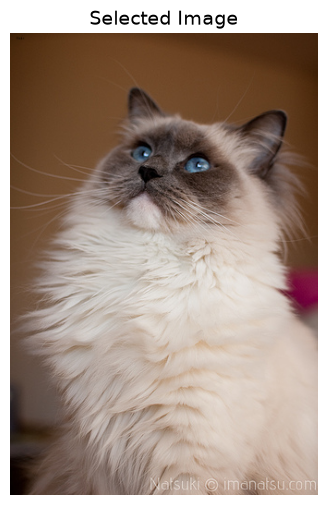


🐱 FINAL RESULT
Animal: CAT
Breed: Ragdoll
Breed Confidence: 85.71%

Top 3 Predictions:
1. Ragdoll - 85.71%
2. Persian - 14.10%
3. Maine Coon - 0.16%


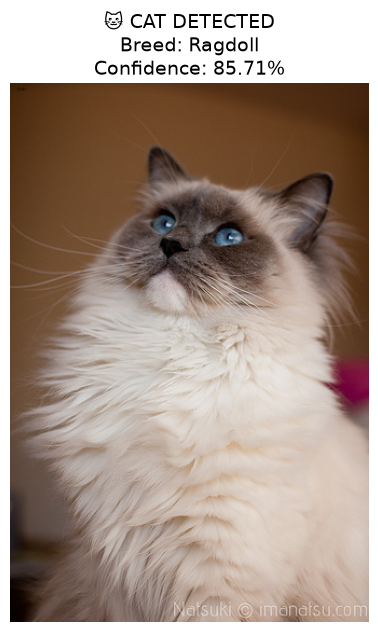

In [14]:
pawcare_unified_predict()

🐾 PAWCARE UNIFIED PET AI


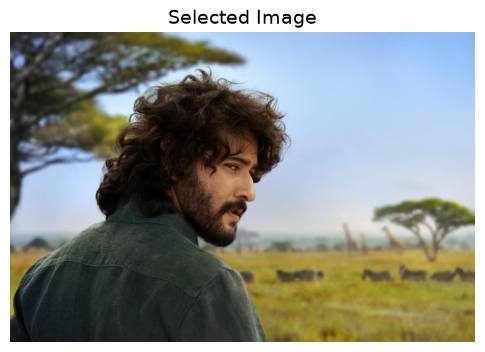


❌ FINAL RESULT
The image is neither a cat nor a dog.
Breed classification skipped.


c:\Users\saisa\OneDrive\Documents\PawCare\venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


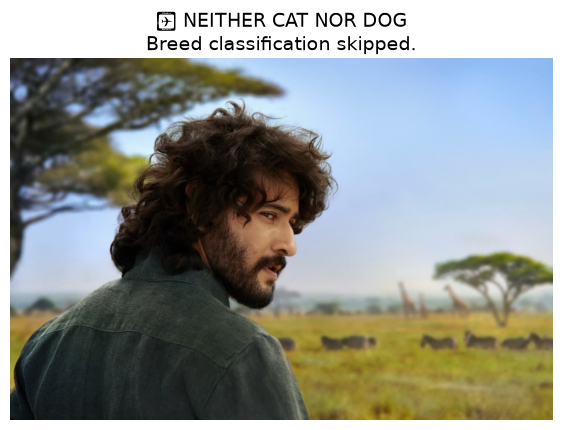

In [15]:
pawcare_unified_predict()


🐾 PAWCARE UNIFIED PET AI


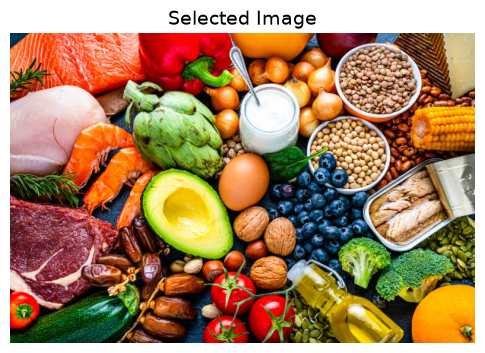


❌ FINAL RESULT
The image is neither a cat nor a dog.
Breed classification skipped.


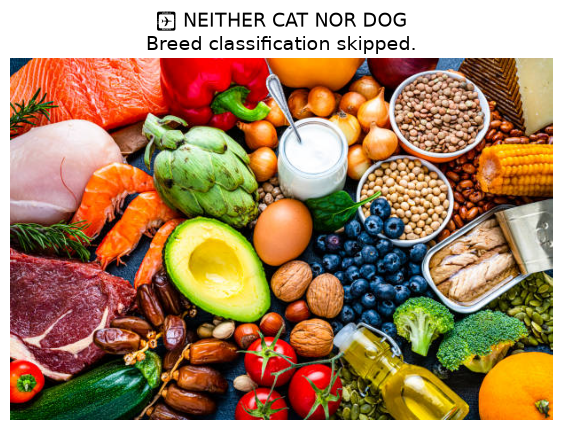

In [17]:
pawcare_unified_predict()